In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("clients.csv", sep=";", decimal=",")
print(df.shape)
df.head()

(4012, 11)


,ID_Client,Date_Ouverture_Compte,Age,Segment,Type_Carte,Nb_Produits,Frais_Mensuels_EUR,Revenu_Annuel_EUR,Solde_Moyen_EUR,Abonnement_Digital,Client_Parti
0,C200281,02/03/2014,20,Particulier,Gold,1,5.09,25781.0,6549.50,Oui,Non
1,C202906,24/06/2023,78,Particulier,Premier,2,5.71,35562.0,5093.42,Oui,Non
2,C203345,16/07/2023,81,Particulier,Classic,1,13.20,30277.0,14566.63,Oui,Non
3,C202965,02/12/2008,83,Particulier,Gold,1,1.32,72358.0,12713.61,Oui,Non
4,C202453,29/03/2006,53,Particulier,Gold,2,8.17,20629.0,6921.41,Oui,Non


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4012 entries, 0 to 4011
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID_Client              4012 non-null   str    
 1   Date_Ouverture_Compte  4012 non-null   str    
 2   Age                    4012 non-null   int64  
 3   Segment                4012 non-null   str    
 4   Type_Carte             4012 non-null   str    
 5   Nb_Produits            4012 non-null   int64  
 6   Frais_Mensuels_EUR     4012 non-null   float64
 7   Revenu_Annuel_EUR      3861 non-null   float64
 8   Solde_Moyen_EUR        4012 non-null   float64
 9   Abonnement_Digital     3952 non-null   str    
 10  Client_Parti           4012 non-null   str    
dtypes: float64(3), int64(2), str(6)
memory usage: 344.9 KB


In [4]:
df.describe()

,Age,Nb_Produits,Frais_Mensuels_EUR,Revenu_Annuel_EUR,Solde_Moyen_EUR
count,4012.000000,4012.000000,4012.000000,3861.000000,4012.000000
mean,51.564307,2.241027,5.197989,40653.844341,8275.736064
std,19.709283,1.154477,3.435764,19436.876187,12276.470818
min,18.000000,1.000000,0.000000,12000.000000,119.580000
25%,34.000000,1.000000,2.500000,27035.000000,2194.550000
50%,52.000000,2.000000,4.435000,36521.000000,4584.435000
75%,69.000000,3.000000,6.480000,49965.000000,9449.937500
max,85.000000,5.000000,14.640000,214077.000000,251380.730000


In [5]:
print(df.isna().sum())
print(df.duplicated().sum())

ID_Client                  0
Date_Ouverture_Compte      0
Age                        0
Segment                    0
Type_Carte                 0
Nb_Produits                0
Frais_Mensuels_EUR         0
Revenu_Annuel_EUR        151
Solde_Moyen_EUR            0
Abonnement_Digital        60
Client_Parti               0
dtype: int64
12


In [6]:
df.nunique()

ID_Client                4000
Date_Ouverture_Compte    3228
Age                        68
Segment                     3
Type_Carte                  3
Nb_Produits                 5
Frais_Mensuels_EUR        960
Revenu_Annuel_EUR        3697
Solde_Moyen_EUR          3993
Abonnement_Digital          2
Client_Parti                2
dtype: int64

In [7]:
df = df.drop_duplicates()
df.shape

(4000, 11)

In [8]:
df["Client_Parti"] = df["Client_Parti"].map({"Oui" : 1, "Non" : 0})
print(df["Client_Parti"].value_counts(dropna=False))
print(df["Client_Parti"].value_counts(normalize=True))

Client_Parti
0    3516
1     484
Name: count, dtype: int64
Client_Parti
0    0.879
1    0.121
Name: proportion, dtype: float64


In [9]:
df.head()

,ID_Client,Date_Ouverture_Compte,Age,Segment,Type_Carte,Nb_Produits,Frais_Mensuels_EUR,Revenu_Annuel_EUR,Solde_Moyen_EUR,Abonnement_Digital,Client_Parti
0,C200281,02/03/2014,20,Particulier,Gold,1,5.09,25781.0,6549.50,Oui,0
1,C202906,24/06/2023,78,Particulier,Premier,2,5.71,35562.0,5093.42,Oui,0
2,C203345,16/07/2023,81,Particulier,Classic,1,13.20,30277.0,14566.63,Oui,0
3,C202965,02/12/2008,83,Particulier,Gold,1,1.32,72358.0,12713.61,Oui,0
4,C202453,29/03/2006,53,Particulier,Gold,2,8.17,20629.0,6921.41,Oui,0


In [12]:
# Conversion du texte en vraie date (format français jour/mois/année)
df["Date_Ouverture_Compte"] = pd.to_datetime(df["Date_Ouverture_Compte"], format="%d/%m/%Y")

# Date de référence : octobre 2026
ref_annee, ref_mois = 2026, 10

df["Anciennete_Mois"] = (
    (ref_annee - df["Date_Ouverture_Compte"].dt.year) * 12
    + (ref_mois - df["Date_Ouverture_Compte"].dt.month)
)

df.head()

,ID_Client,Date_Ouverture_Compte,Age,Segment,Type_Carte,Nb_Produits,Frais_Mensuels_EUR,Revenu_Annuel_EUR,Solde_Moyen_EUR,Abonnement_Digital,Client_Parti,Anciennete_Mois
0,C200281,2014-03-02,20,Particulier,Gold,1,5.09,25781.0,6549.50,Oui,0,151
1,C202906,2023-06-24,78,Particulier,Premier,2,5.71,35562.0,5093.42,Oui,0,40
2,C203345,2023-07-16,81,Particulier,Classic,1,13.20,30277.0,14566.63,Oui,0,39
3,C202965,2008-12-02,83,Particulier,Gold,1,1.32,72358.0,12713.61,Oui,0,214
4,C202453,2006-03-29,53,Particulier,Gold,2,8.17,20629.0,6921.41,Oui,0,247


In [16]:
x = df.drop("Client_Parti", axis=1)
y = df["Client_Parti"]

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [27]:
numeric_features = [
    "Age",
    "Nb_Produits",
    "Frais_Mensuels_EUR",
    "Revenu_Annuel_EUR",
    "Solde_Moyen_EUR",
    "Anciennete_Mois"
]

categorical_features = [
    "Segment",
    "Type_Carte",
    "Abonnement_Digital"
]

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [29]:
numeric_transformer= Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [30]:
from sklearn.linear_model import LogisticRegression

In [31]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ]
)

In [32]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['ID_Client','Date_Ouverture_Compte','Age',...,'Solde_Moyen_EUR', 'Abonnement_Digital','Anciennete_Mois']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By speci

In [33]:
model.named_steps["classifier"].n_iter_

array([10], dtype=int32)

In [34]:
y_pred = model.predict(X_test)

In [36]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print("Départ prédits :", y_pred.sum())
print("Départ réels :", y_test.sum())
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("AUC :", roc_auc_score(y_test, model.predict_proba(X_test)[:,1]))

Départ prédits : 311
Départ réels : 97
[[449 254]
 [ 40  57]]
              precision    recall  f1-score   support

           0       0.92      0.64      0.75       703
           1       0.18      0.59      0.28        97

    accuracy                           0.63       800
   macro avg       0.55      0.61      0.52       800
weighted avg       0.83      0.63      0.70       800

AUC : 0.6524907979058819


 seuil  clients_signales  depart_detectes  fausses_alertes  depart_manques  rappel  precision  cout_total
  0.30               704               91              613               6   0.938      0.129       37600
  0.35               627               87              540              10   0.897      0.139       35350
  0.40               525               77              448              20   0.794      0.147       34250
  0.45               410               68              342              29   0.701      0.166       32100
  0.50               311               57              254              40   0.588      0.183       31550
  0.55               216               46              170              51   0.474      0.213       31200
  0.60               135               29              106              68   0.299      0.215       33950
  0.65                78               20               58              77   0.206      0.256       34700
  0.70                40               13     

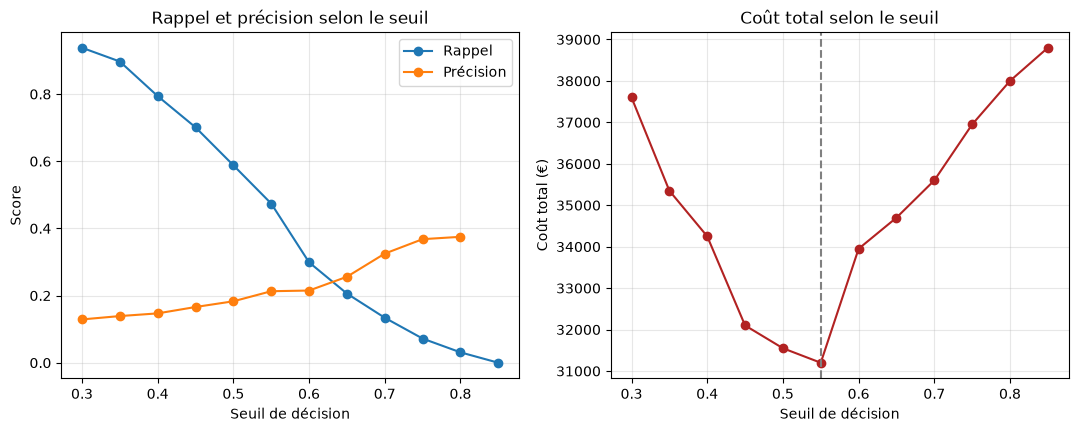

In [38]:
import matplotlib.pyplot as plt

probas = model.predict_proba(X_test)[:, 1]

# 1. Tableau des résultats pour chaque seuil
lignes = []
for seuil in np.arange(0.30, 0.86, 0.05):
    pred = (probas >= seuil).astype(int)
    vp = ((pred == 1) & (y_test == 1)).sum()   # depart détectés
    fp = ((pred == 1) & (y_test == 0)).sum()   # depart signalés à tort
    fn = ((pred == 0) & (y_test == 1)).sum()   # depart manqués
    lignes.append({
        "seuil": round(seuil, 2),
        "clients_signales": pred.sum(),
        "depart_detectes": vp,
        "fausses_alertes": fp,
        "depart_manques": fn,
        "rappel": round(vp / (vp + fn), 3),
        "precision": round(vp / pred.sum(), 3) if pred.sum() > 0 else np.nan,
    })
resultats = pd.DataFrame(lignes)

# 2. Coût total selon des hypothèses métier (à adapter)
COUT_CONTACT = 50           # coût d'un contact client (en €)
COUT_Depart_MANQUE = 400  # perte estimée pour un insatisfait non traité (en €)
resultats["cout_total"] = (resultats["clients_signales"] * COUT_CONTACT
                           + resultats["depart_manques"] * COUT_Depart_MANQUE)
print(resultats.to_string(index=False))

meilleur = resultats.loc[resultats["cout_total"].idxmin()]
print(f"\nSeuil le moins coûteux : {meilleur['seuil']} "
      f"(coût total : {meilleur['cout_total']:,.0f} €)")

# 3. Visualisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(resultats["seuil"], resultats["rappel"], marker="o", label="Rappel")
ax1.plot(resultats["seuil"], resultats["precision"], marker="o", label="Précision")
ax1.set_xlabel("Seuil de décision"); ax1.set_ylabel("Score")
ax1.set_title("Rappel et précision selon le seuil"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(resultats["seuil"], resultats["cout_total"], marker="o", color="firebrick")
ax2.axvline(meilleur["seuil"], linestyle="--", color="grey")
ax2.set_xlabel("Seuil de décision"); ax2.set_ylabel("Coût total (€)")
ax2.set_title("Coût total selon le seuil"); ax2.grid(alpha=0.3)
plt.show()